In [1]:
# Fetch hourly PM2.5 data (CAMS model via Open-Meteo) for Saharanpur, Oct-Nov 2025
import requests
import pandas as pd

url = "https://air-quality-api.open-meteo.com/v1/air-quality?latitude=29.96&longitude=77.55&hourly=pm2_5,pm10&start_date=2025-10-01&end_date=2025-11-30&timezone=Asia/Kolkata"
r = requests.get(url)
js = r.json()
df = pd.DataFrame(js["hourly"])
df["time"] = pd.to_datetime(df["time"])
df["date"] = df["time"].dt.date
df["month"] = df["time"].dt.strftime("%b")
df["hour"] = df["time"].dt.hour
print(df.shape)
print(df["pm2_5"].describe())

(1464, 6)
count    1464.000000
mean       71.307855
std        31.944213
min        13.500000
25%        47.500000
50%        66.100000
75%        90.100000
max       197.000000
Name: pm2_5, dtype: float64


Worst day: 2025-11-22 140.4
Cleanest day: 2025-10-07 26.4
month
Nov    80.8
Oct    62.2
Name: pm2_5, dtype: float64
Days above 60: 42 of 61


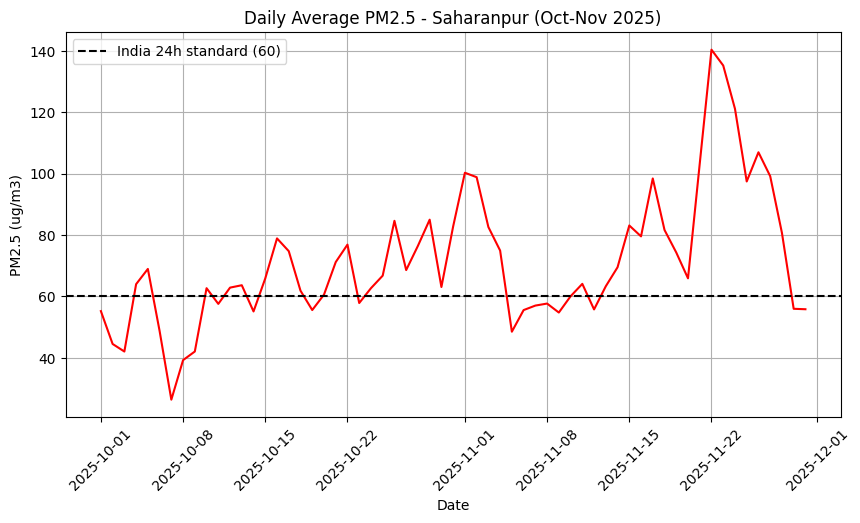

In [2]:
# Daily average PM2.5 and days above India's 24-hour standard (60 ug/m3)
import matplotlib.pyplot as plt

daily = df.groupby("date")["pm2_5"].mean()
print("Worst day:", daily.idxmax(), round(daily.max(), 1))
print("Cleanest day:", daily.idxmin(), round(daily.min(), 1))
print(df.groupby("month")["pm2_5"].mean().round(1))
print("Days above 60:", int((daily > 60).sum()), "of", len(daily))

plt.figure(figsize=(10, 5))
plt.plot(daily.index, daily.values, color="red")
plt.axhline(60, color="black", linestyle="--", label="India 24h standard (60)")
plt.title("Daily Average PM2.5 - Saharanpur (Oct-Nov 2025)")
plt.xlabel("Date")
plt.ylabel("PM2.5 (ug/m3)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

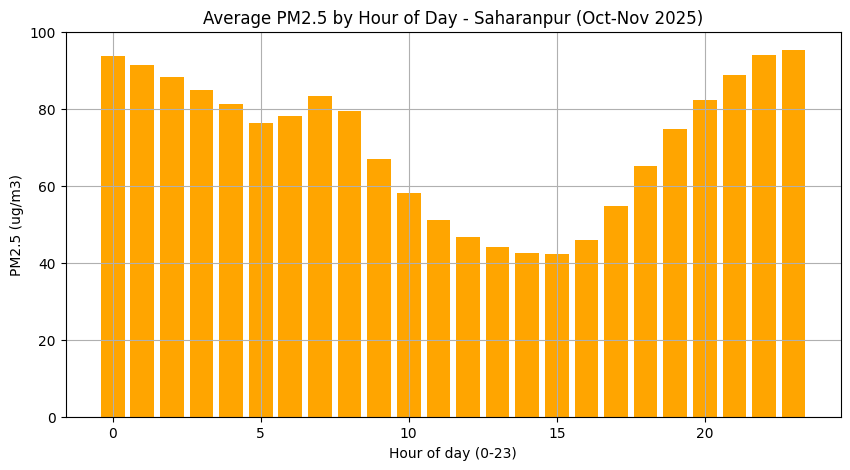

Most polluted hour: 23 95.4
Cleanest hour: 15 42.4


In [3]:
# Average PM2.5 by hour of day
hourly = df.groupby("hour")["pm2_5"].mean()

plt.figure(figsize=(10, 5))
plt.bar(hourly.index, hourly.values, color="orange")
plt.title("Average PM2.5 by Hour of Day - Saharanpur (Oct-Nov 2025)")
plt.xlabel("Hour of day (0-23)")
plt.ylabel("PM2.5 (ug/m3)")
plt.grid(True)
plt.show()

print("Most polluted hour:", hourly.idxmax(), round(hourly.max(), 1))
print("Cleanest hour:", hourly.idxmin(), round(hourly.min(), 1))